# Kmeans

Ce notebook présente une implémentation de l'algorithme du KMeans qui peut être appliqué à des dimensions quelconques. Une version spécifique au traitement d'image sera aussi présenté.

Testé avec :
- Python 3.13.12
- numpy==2.3.4
- scipy==1.16.3
- skimage==0.25.2

In [1]:
# Imports and fixing the seed
import numpy as np
import matplotlib.pyplot as plt
import scipy
import skimage

np.random.seed(789)

In [2]:
!python --version

Python 3.13.12


In [3]:
print('\n'.join(f'{m.__name__}=={m.__version__}' for m in globals().values() if getattr(m, '__version__', None)))

numpy==2.3.4
scipy==1.16.3
skimage==0.25.2


## Chargement des données de tests

### Génération de clusters quelconques

Génération de clusters suivant une loi gaussienne aux paramètres aléatoires

In [4]:
def generate_random_cluster(nb_cluster, nb_points_per_cluster=50, dimension=2):
    random_generated_data = np.zeros((nb_points_per_cluster * nb_cluster, dimension))
    # Create all the points following the normal law for each cluster
    for i in range(nb_cluster):
        # Create the distribution
        mu = np.random.randint(100)
        sigma = np.random.randint(5)
        distrib = np.random.normal(mu, sigma, (nb_points_per_cluster, dimension))
        # add the genarated points to  
        random_generated_data[i*nb_points_per_cluster: (i+1)*nb_points_per_cluster] = distrib
    np.random.shuffle(random_generated_data) # shuffle to avoid biais when tested
    return random_generated_data

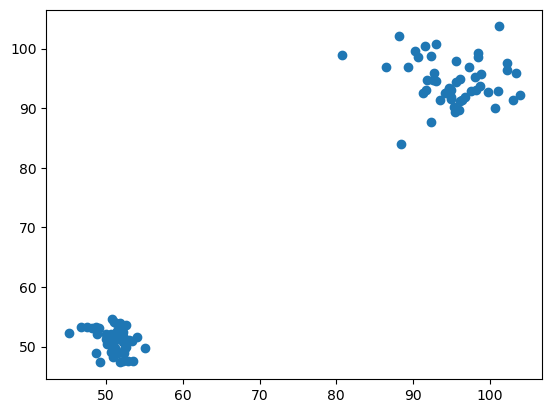

In [5]:
random_generated_2_cluster = generate_random_cluster(2)

# Show data on graph
plt.scatter(random_generated_2_cluster[:,0], random_generated_2_cluster[:,1])
plt.show()

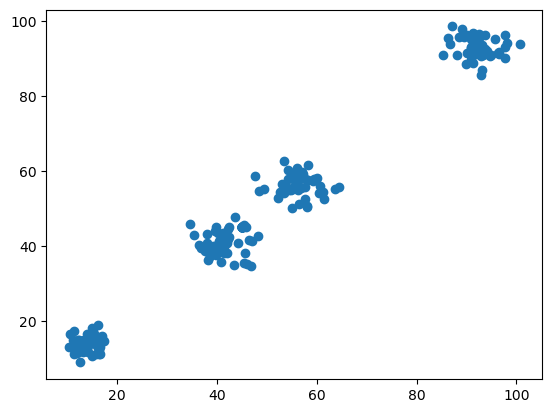

In [6]:
random_generated_5_cluster= generate_random_cluster(5)

# Show data on graph
plt.scatter(random_generated_5_cluster[:,0], random_generated_5_cluster[:,1])
plt.show()

### Import des données du fichier .csv

Import du jeu de test depuis le fichier représentant 6 classes

[[2.38360866 1.46715007]
 [2.20152865 1.63564779]
 [2.36495777 1.26597762]
 ...
 [2.49055014 2.24624783]
 [2.3978519  2.05521342]
 [2.59315747 1.93219502]]


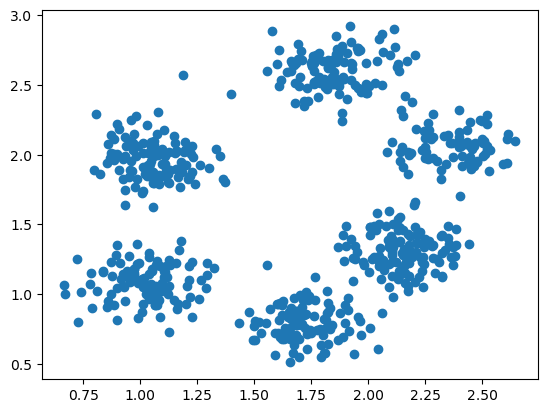

In [7]:
data_from_file = np.genfromtxt("data/kmeans_6_classes.csv", delimiter=";", skip_header=1)
print(data_from_file)
np.random.shuffle(data_from_file) # shuffle to avoid biais when tested

# Show data on graph
plt.scatter(data_from_file[:,0], data_from_file[:,1])
plt.show()

### Importation des données d'image

Import d'une image sous forme de tableau RVB

raw data: 
 shape:(279, 370, 3)
 data: [[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]]
flatten lines data: 
 shape: (103230, 3)
 data: [[255 255 255]
 [255 255 255]
 [255 255 255]
 ...
 [255 255 255]
 [255 255 255]
 [255 255 255]]


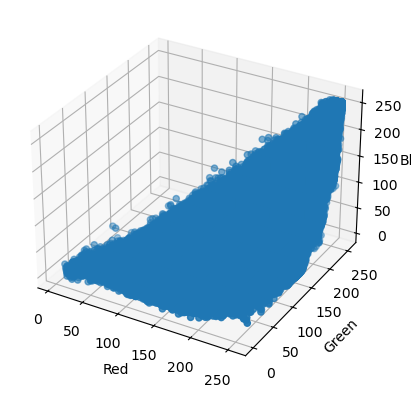

In [8]:
# Generate RGB array from image
data_from_image = skimage.io.imread("data/fruits.jpg")
print(f"raw data: \n shape:{data_from_image.shape}\n data: {data_from_image}")

# Reshaping the image to flatten all the lines
data_from_image_reshape = data_from_image.reshape(-1, 3)
print(f"flatten lines data: \n shape: {data_from_image_reshape.shape}\n data: {data_from_image_reshape}")

# Show image on RGB figure
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.set_xlabel('Red')
ax.set_ylabel('Green')
ax.set_zlabel('Blue')
ax.scatter(data_from_image_reshape[:,0], data_from_image_reshape[:,1], data_from_image_reshape[:,2])
plt.show()

## Définition du Kmeans

### Description de l'implémentation

#### Caractéristique
- Fonctionnement sur des dimensions quelconques
- Complexité temporelle de l'entrainementen $O(n*d*k*I)$
- La complexité en espace est donc en $O(n*d*k)$

> $n$ représente le nombre de données d'entrainements, $d$ la dimension du problème, $k$ le nombre de cluster à identifier, $I$ le nombre d'itération avant convergence

#### Structure de données
Cette version de KMeans stocke :
- les données d'entrainements
- l'ensemble des centroïds
- la matrice de distance
- un tableau permettant de faire l'association au cluster

#### Principe de l'entrainement
1. Initialisation du cluster avec des centroids aléatoires
2. Boucle tant que les centroids ne sont pas stables
    1. Calculer les centroides
    2. Mettre à jour la matrice de distance
    3. Mettre à jour l'association des points à leur cluster

#### Piste d'amélioration
- Choisir le type de distance à utiliser
- Ajouter une fonction de prédiction pour tester une valeur en dehors du jeu de test
- Pouvoir laisser le choix à l'utilisateur d'utiliser une version avec une empreinte mémoire plus faible (exemple : ne pas stocker la matrice de distance)
- Généraliser les fonctions d'affichages pour choisir les dimensions à afficher dans le cas où on est sur plus de 2 dimensions
- Mise en place d'heuristique pour favoriser une meilleure initialisation des centroïds

### L'implémentation de Kmeans

In [9]:
class Kmeans():
    def __init__(self, x_train, k):
        self.k = k
        self.x_train = x_train
        self.centroids = np.zeros((self.k, self.x_train.shape[1]))
        self.dist_matrix = np.zeros((len(self.x_train), self.k))
        self.cluster = np.zeros(len(self.x_train))

    def init_centroids(self):
        """
        Choose random centroids from the data
        """
        inds = np.random.choice(len(self.x_train), self.k)
        self.centroids[:] = self.x_train[inds]

    def dist_calc(self):
        """
        Update the distance matrix
        """
        self.dist_matrix = scipy.spatial.distance.cdist(self.x_train, self.centroids)

    def agglomerate(self):
        """
        Update the association of point with the closest cluster
        """
        # Probablement une meilleure écriture plus Python (liste en comprehension ?, version numpy plus opti ?)
        for i, e in enumerate(self.dist_matrix):
            self.cluster[i] = np.argmin(e)

    def get_point_of_cluster(self, cluster_index):
        in_matrix = (self.cluster == cluster_index)
        return self.x_train[in_matrix]

    def plot_cluster(self):
        for ci in range(self.k):
            x_cluster = self.get_point_of_cluster(ci)
            plt.scatter(x_cluster[:,0], x_cluster[:,1])
            plt.scatter(self.centroids[ci][0], self.centroids[ci][1], marker='x', linewidths=10)
        plt.show()

    def new_centroids_calc(self):
        for ci in range(self.k):
            in_matrix = self.get_point_of_cluster(ci)
            if in_matrix.size != 0:
                self.centroids[ci] = np.mean(in_matrix, axis=0)

    def get_centroid_from_cluster(self, ci):
        return self.centroids[ci]

    def init_cluster(self):
        """
        Choose random centroid and calculate the first association
        """
        self.init_centroids()
        self.dist_calc()
        self.agglomerate()

    def fit(self, debug=False, ceil=0.05, fake_init=None):
        """
        Apply the full Kmean algorithm to fit with the data.
        @debug: bool - choose if the cluster is plot after each step
        """
        if fake_init is None:
            self.init_cluster()
        else:
            # Pas très propre - sert uniquement à piper les tests pour montrer des cas d'initialisations spécifique
            self.centroids = fake_init
            self.dist_calc()
            self.agglomerate()
            if debug: self.plot_cluster()
        old_centroids = np.zeros(self.centroids.shape)
        while not(np.all(abs(old_centroids-self.centroids) < ceil)):
            old_centroids = self.centroids.copy()
            self.new_centroids_calc()
            self.dist_calc()
            self.agglomerate()
            if debug: self.plot_cluster()
            


Dans le cas d'ume image, on s'assure de pouvoir réutiliser la classe ci dessus. Pour ce faire, il faut avoir les données en 2 dimensions et non 3. Pour ce faire, on détruit la dimension représentant les lignes de l'image pour n'avoir qu'une seule ligne. On prendra le soit de stocker la dimension initiale de l'image pour être en capacité de la reconstruire.

Une adaptation est nécessaire pour l'affichage avec un besoin d'affichage sur les 3 dimensions de couleurs. De la même façon, une méthode de construction d'image à partir des clusters est incluse.

In [10]:
class Kmeans_image(Kmeans):
    def __init__(self, x_train, k):
        self.img_shape = x_train.shape # Store the shape to reconstruct the image after applying the clustering
        x_train = x_train.reshape(-1, 3) # Flatten the RGB into one line only
        super().__init__(x_train, k)

    def plot_cluster(self):
        fig = plt.figure()
        ax = fig.add_subplot(projection='3d')
        ax.set_xlabel('Red')
        ax.set_ylabel('Green')
        ax.set_zlabel('Blue')
        for ci in range(self.k):
            x_cluster = self.get_point_of_cluster(ci)
            centroid = self.centroids[ci][0], self.centroids[ci][1], self.centroids[ci][2]
            # Colorier avec la couleur moyenne des clusters
            color = [np.array(centroid) / 255]
            ax.scatter(x_cluster[:,0], x_cluster[:,1], x_cluster[:,2], c=color)
            plt.scatter(*centroid, marker='x', linewidths=10, colorizer=color)
        plt.show()
        
    def construct_image_from_cluster(self):
        """
        Construct the image based on the color of the centroid of each cluster.
        """
        img_cluster = np.zeros((self.img_shape))
        for i in range(self.img_shape[0]):
            for j in range(self.img_shape[1]):
                ci = self.cluster[i*self.img_shape[1] + j]
                img_cluster[i,j] = self.get_centroid_from_cluster(int(ci))
        return img_cluster.astype(np.uint8)
        
        

### Tests successifs des méthodes - vocation à du débogage

#### Tests successifs des méthodes - Kmeans classique

In [11]:
k = 3
cluster = Kmeans(random_generated_2_cluster, k)
cluster.init_centroids()
print(cluster.centroids)

[[ 52.00236553  51.82994982]
 [ 86.41095648  96.86750397]
 [103.90219716  92.30580894]]


In [12]:
cluster.dist_calc()
print(cluster.dist_matrix)

[[ 1.31243827 57.8083531  67.07866446]
 [64.13864809 12.46318322  6.09897646]
 [ 1.62368143 56.56576589 65.29482153]
 [63.98482775 15.16848184  2.91128462]
 [ 2.91997797 59.40736194 68.20174117]
 [ 2.01207133 57.87861947 66.57023788]
 [ 4.51745006 59.24696846 67.36039715]
 [60.93212523  9.49302205  8.58365032]
 [ 0.         56.67744186 65.81707754]
 [62.8906703  13.91148096  4.21633423]
 [58.58782858  8.89643728  9.73802749]
 [67.75409133 17.07021361  3.63469602]
 [ 1.04153561 56.35827705 65.75850947]
 [59.13172924  6.93903531 11.18525373]
 [65.90717718 12.11407271  8.39727485]
 [ 2.36312446 58.97076439 68.18013945]
 [60.67513315  4.59482463 14.64453952]
 [ 0.81758048 56.65994182 66.0062229 ]
 [ 3.68394532 60.14600732 68.8680182 ]
 [ 3.0224605  55.2210438  65.07538311]
 [ 4.68871667 58.38562166 68.53913524]
 [59.12612098  6.56063338 11.53939757]
 [ 5.12484296 61.78310879 70.65893627]
 [61.63483293  9.94452827  8.15942163]
 [ 1.99118434 55.63482382 64.37255684]
 [ 2.99550126 59.63143521

In [13]:
cluster.agglomerate()
print(cluster.cluster)

[0. 2. 0. 2. 0. 0. 0. 2. 0. 2. 1. 2. 0. 1. 2. 0. 1. 0. 0. 0. 0. 1. 0. 2.
 0. 0. 0. 1. 0. 1. 0. 0. 2. 0. 2. 2. 1. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0. 0.
 2. 0. 0. 1. 0. 2. 2. 0. 1. 0. 2. 0. 0. 1. 2. 0. 2. 1. 0. 2. 0. 0. 0. 2.
 0. 0. 1. 2. 0. 0. 2. 1. 0. 2. 1. 0. 2. 0. 1. 0. 2. 2. 0. 2. 0. 1. 2. 1.
 2. 1. 2. 0.]


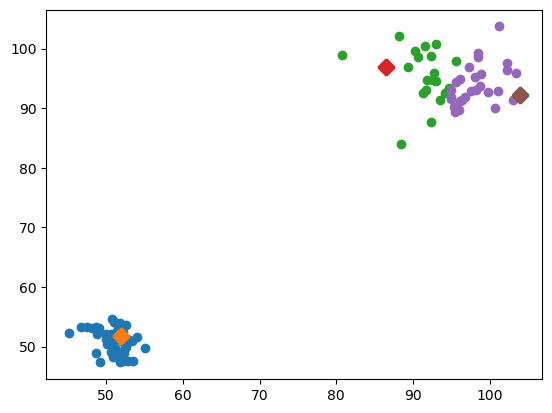

In [14]:
cluster.plot_cluster()

In [15]:
print(cluster.centroids)
cluster.new_centroids_calc()
print(cluster.centroids)

[[ 52.00236553  51.82994982]
 [ 86.41095648  96.86750397]
 [103.90219716  92.30580894]]
[[51.05835347 51.09689391]
 [91.30774957 95.37917818]
 [98.41490618 93.85563806]]


#### Tests successifs des méthodes - Kmeans image

In [16]:
k = 2
cluster_image = Kmeans_image(data_from_image, k)
cluster_image.init_centroids()
print(cluster_image.centroids)

[[249. 246. 241.]
 [255. 255. 255.]]


In [17]:
cluster_image.dist_calc()
print(cluster_image.dist_matrix)

[[17.69180601  0.        ]
 [17.69180601  0.        ]
 [17.69180601  0.        ]
 ...
 [17.69180601  0.        ]
 [17.69180601  0.        ]
 [17.69180601  0.        ]]


In [18]:
cluster_image.agglomerate()
print(cluster_image.cluster)

[1. 1. 1. ... 1. 1. 1.]


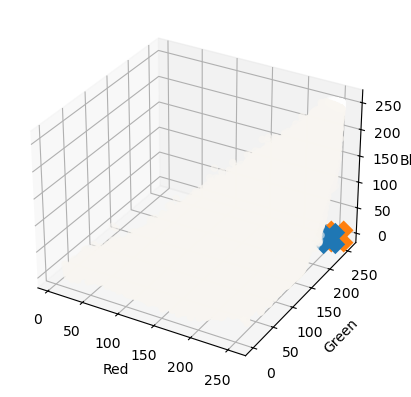

In [19]:
cluster_image.plot_cluster()

In [20]:
print(cluster_image.centroids)
cluster_image.new_centroids_calc()
print(cluster_image.centroids)

[[249. 246. 241.]
 [255. 255. 255.]]
[[172.50948895 121.10660221  65.38254144]
 [254.71955887 254.74842686 254.54807006]]


### Entrainements complets sur les jeux de données 

#### Recherche de 2 clusters parmis 2 clusters - problème à 2 dimensions

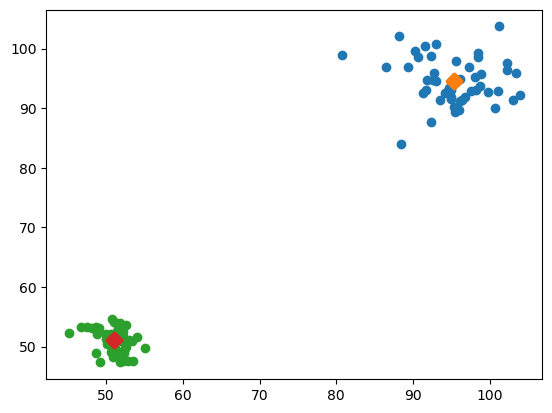

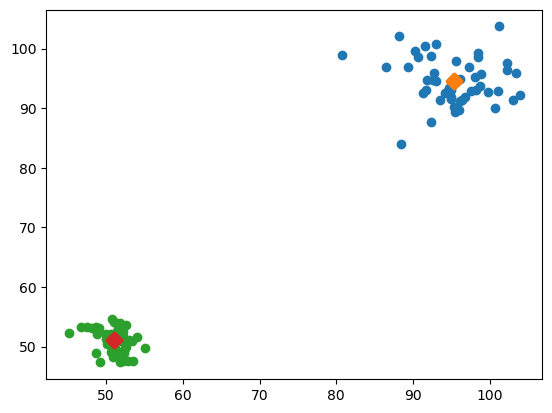

In [21]:
k = 2
cluster_to_fit = Kmeans(random_generated_2_cluster, k)
cluster_to_fit.fit(debug=True)

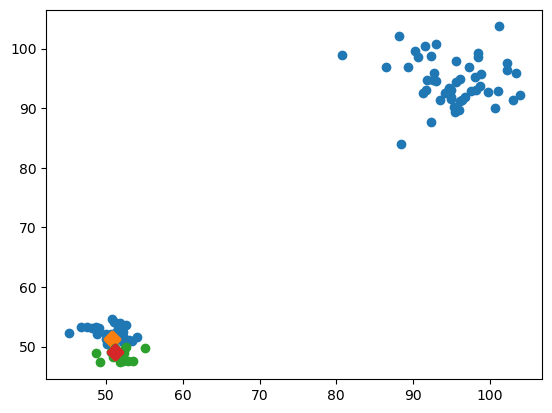

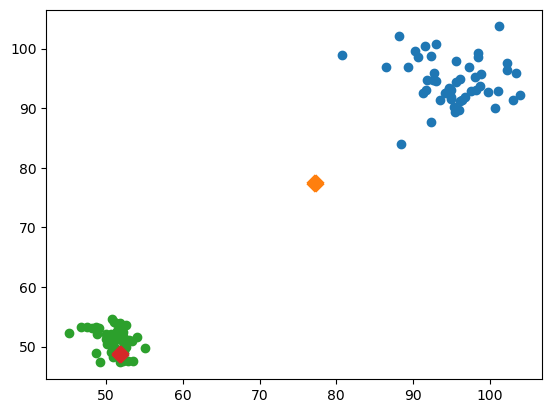

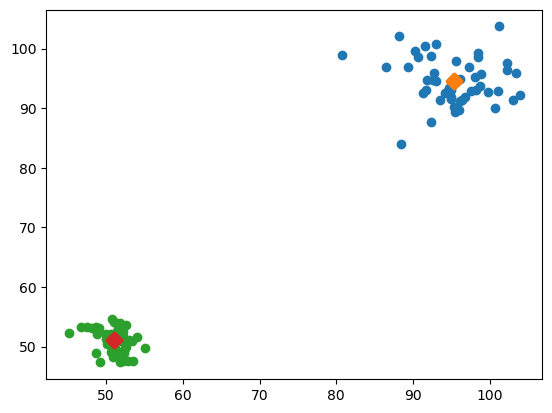

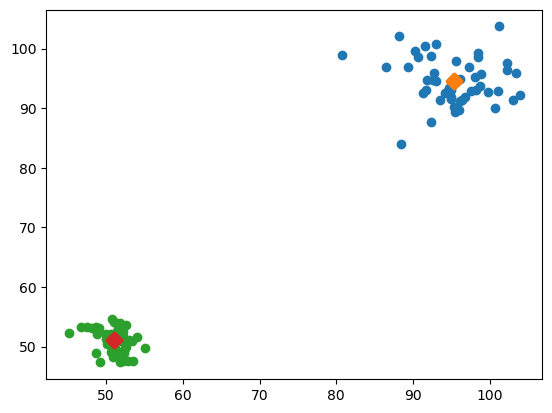

In [22]:
k = 2
cluster_to_fit = Kmeans(random_generated_2_cluster, k)
fake_centroids = np.array([[50.7837158, 51.34272601], [ 51.1937917, 49.02415587]]) # Pick two close point from one of the distribution
cluster_to_fit.fit(debug=True, fake_init=fake_centroids)

Dans le premier cas, on remarque que l'on a une initialisation favorable à la convergence. La convergence est alors très rapide et les deux distibutions sont correctements identifiés.

Dans le second cas où l'on force une "mauvaise" initialisation (on force les deux centroïdes à être dans le même cluster). On arrive tout de même à retrouver le résultat attendu.

#### Recherche de 2 clusters parmis 5 clusters - problème à 2 dimensions

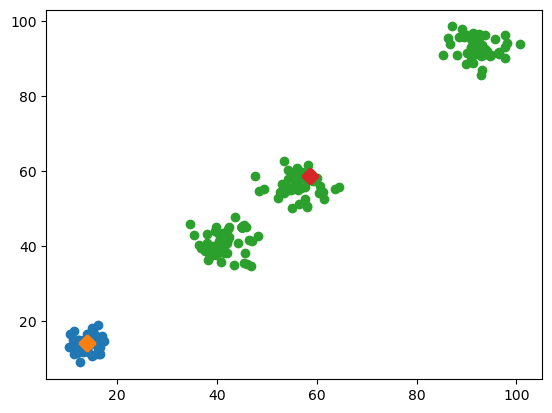

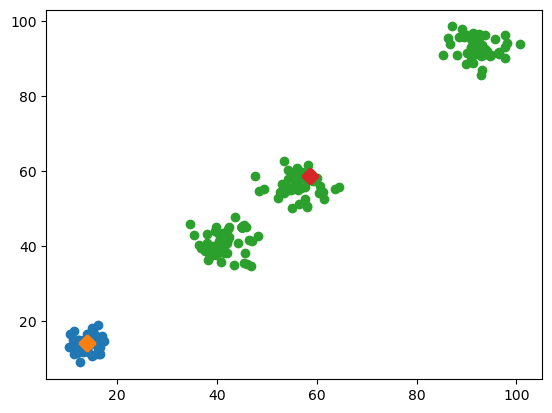

In [23]:
k = 2
cluster_to_fit = Kmeans(random_generated_5_cluster, k)
cluster_to_fit.fit(debug=True)

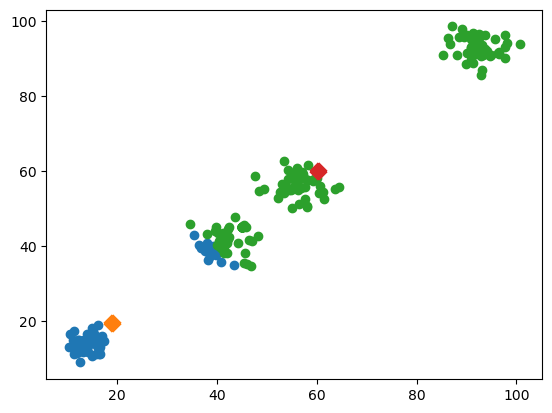

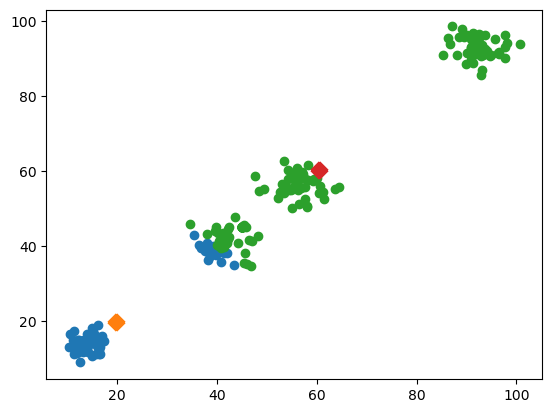

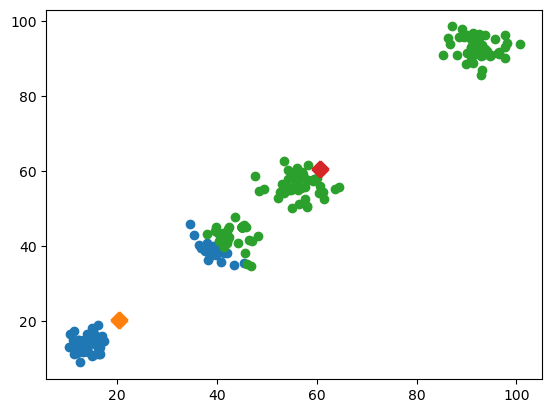

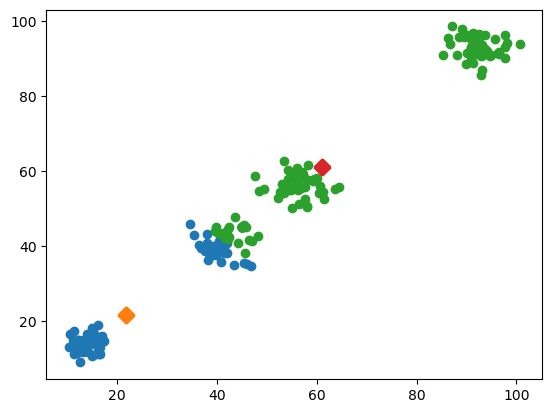

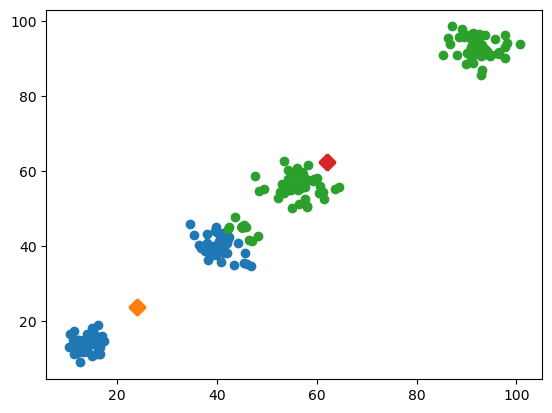

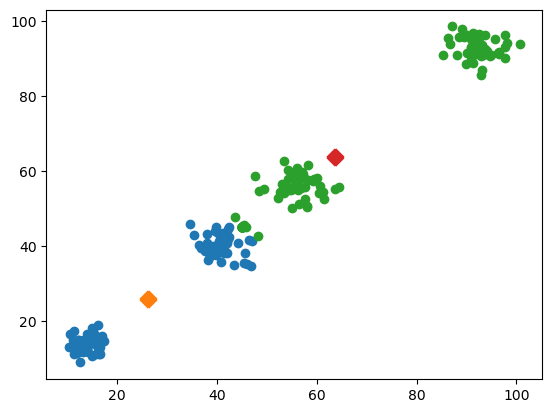

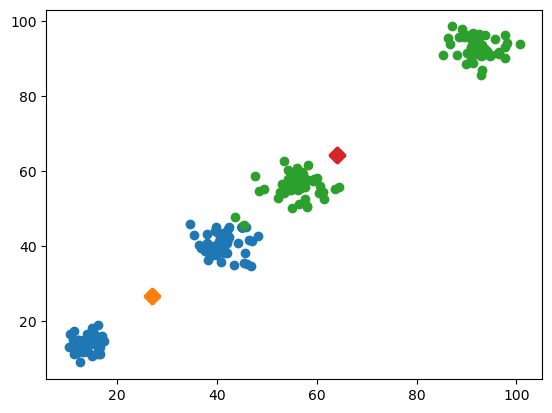

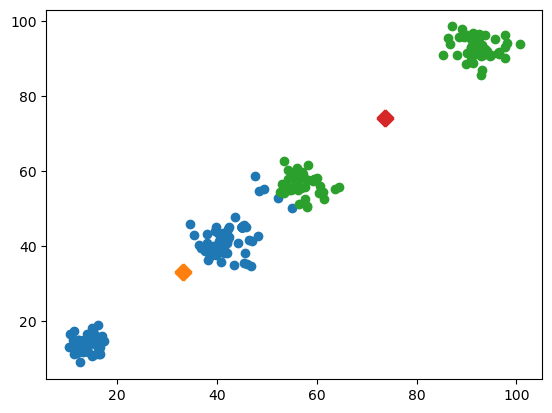

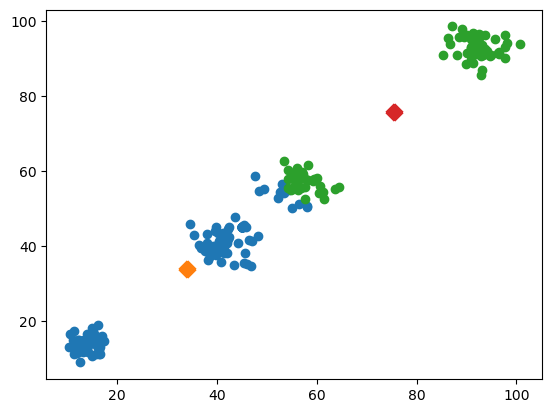

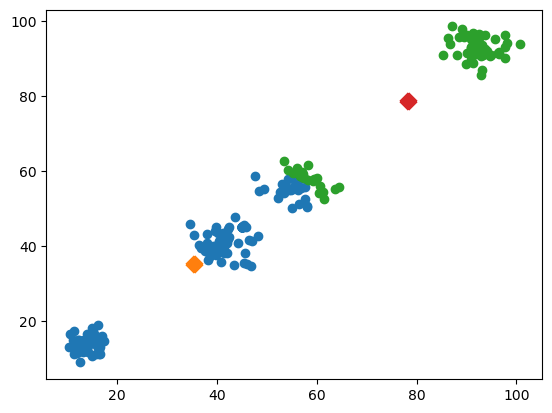

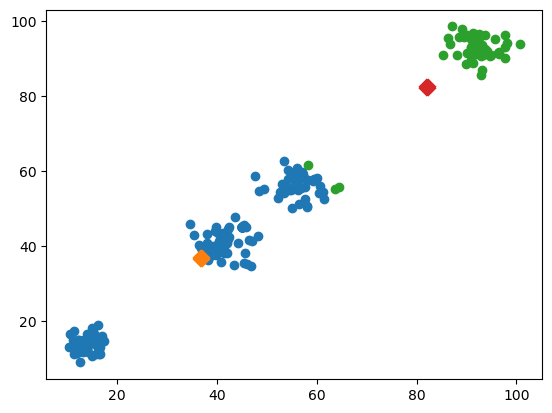

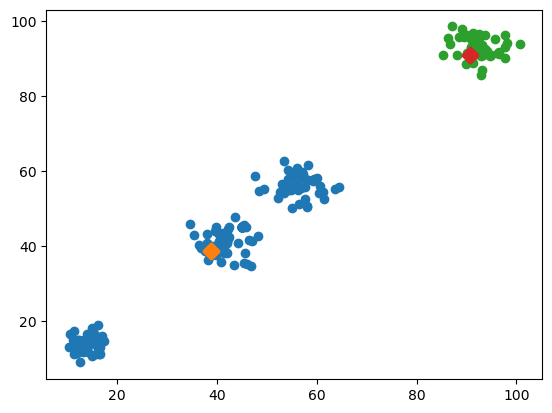

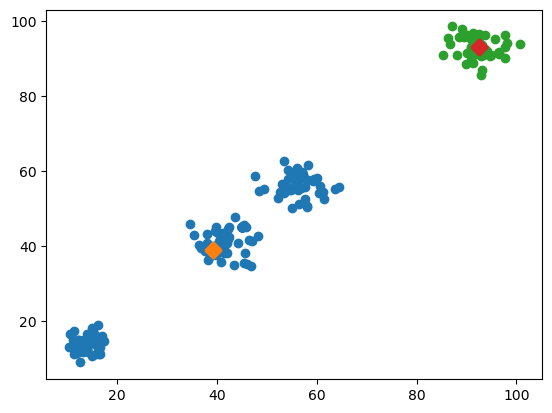

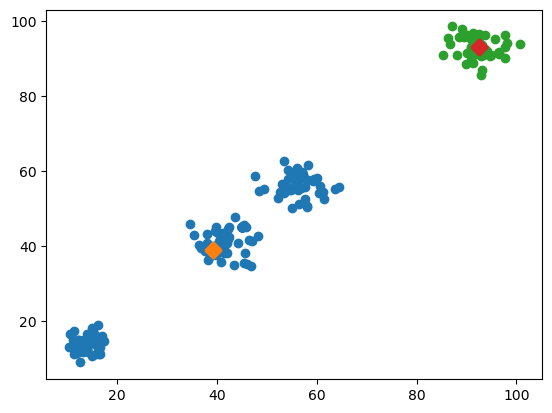

In [24]:
k = 2
cluster_to_fit = Kmeans(random_generated_5_cluster, k)
cluster_to_fit.fit(debug=True)

Dans ce cas à 5 distributions (2 étant entremêlés), on voit que les distributions sont individuellement dans un même cluster. Ce qui est un résultat souhaitable.

Pour autant, si l'on compare les deux exécutions, on voit que l'initialisation change le regroupement des distributions.

#### Recherche des 6 clusters parmis le jeu de données imposé

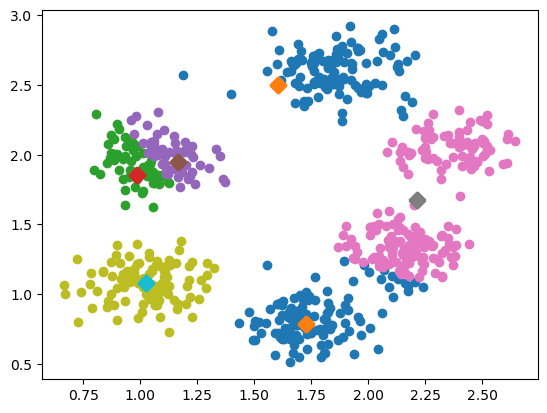

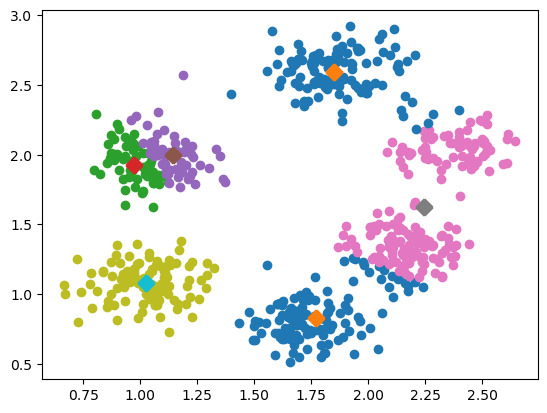

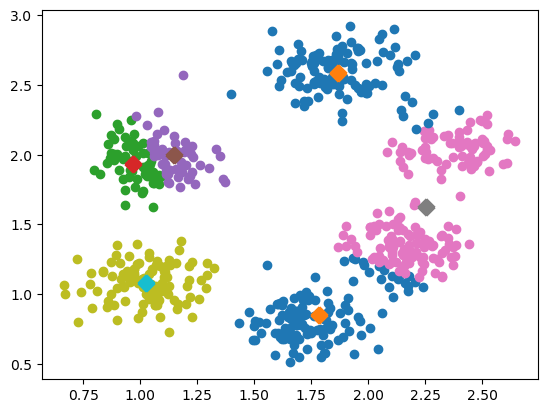

In [25]:
k = 6
cluster_data_from_file = Kmeans(data_from_file, k)
cluster_data_from_file.fit(debug=True)

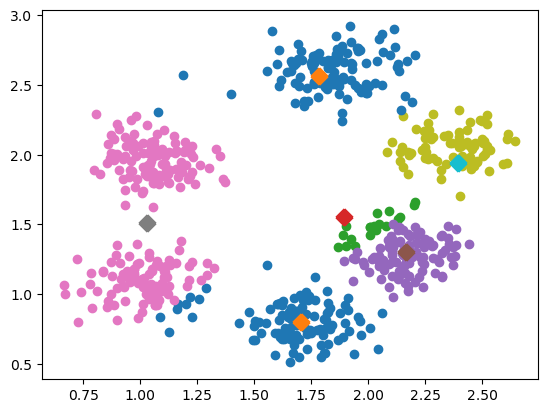

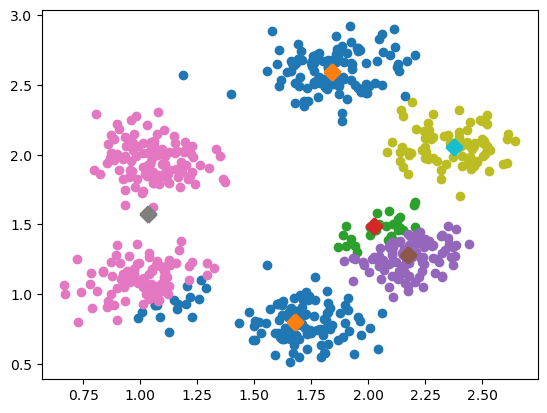

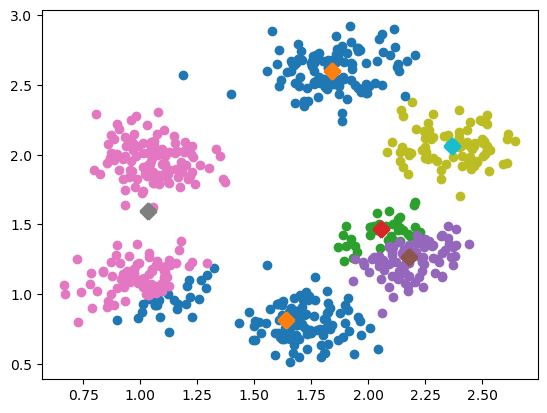

In [26]:
k = 6
cluster_data_from_file = Kmeans(data_from_file, k)
cluster_data_from_file.fit(debug=True)

Cette exemple nous montre bien la sensibilité de l'initialisation. A partir des mêmes données d'entrées, les clusters résultant sont différents.

On remarque aussi du fait de la proximité relative des clusters, quelques difficultés sont rencontrés pour identifier correctement les clusters.

#### Partionnement d'une image en 2

[[[250 247 240]
  [250 247 240]
  [250 247 240]
  ...
  [250 247 240]
  [250 247 240]
  [250 247 240]]

 [[250 247 240]
  [250 247 240]
  [250 247 240]
  ...
  [250 247 240]
  [250 247 240]
  [250 247 240]]

 [[250 247 240]
  [250 247 240]
  [250 247 240]
  ...
  [250 247 240]
  [250 247 240]
  [250 247 240]]

 ...

 [[250 247 240]
  [250 247 240]
  [250 247 240]
  ...
  [250 247 240]
  [250 247 240]
  [250 247 240]]

 [[250 247 240]
  [250 247 240]
  [250 247 240]
  ...
  [250 247 240]
  [250 247 240]
  [250 247 240]]

 [[250 247 240]
  [250 247 240]
  [250 247 240]
  ...
  [250 247 240]
  [250 247 240]
  [250 247 240]]]


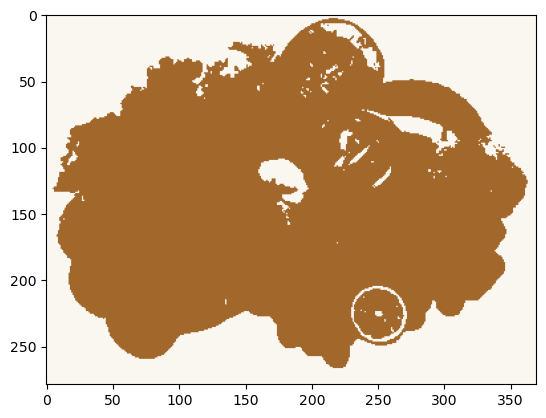

In [27]:
k = 2
cluster_image_fit = Kmeans_image(data_from_image, k)
cluster_image_fit.fit(debug=False)

img_arr_reconstruct = cluster_image_fit.construct_image_from_cluster()
print(img_arr_reconstruct)
plt.imshow(img_arr_reconstruct)
plt.show()
skimage.io.imsave("out/reconstructed_fruit.jpg", img_arr_reconstruct)

Appliqué à une image, l'algorithme de KMeans peut aider à différencier des contours. Pour autant, quelques artefacts persistent comme sur les objets ayant une couleurs trop similaires au fond comme l'ail au milieu ou le citron vert.

L'un des points notables, est la stabilité des résultats malgré une initialisation aléatoire.

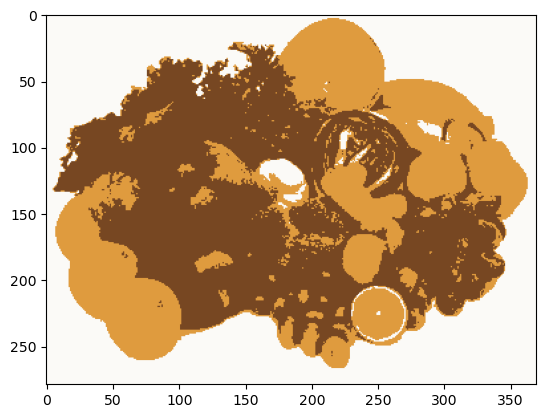

In [28]:
k = 3
cluster_3_image_fit = Kmeans_image(data_from_image, k)
cluster_3_image_fit.fit(debug=False, ceil=1)

cluster_3_image_reconstruct = cluster_3_image_fit.construct_image_from_cluster()
plt.imshow(cluster_3_image_reconstruct)
plt.show()

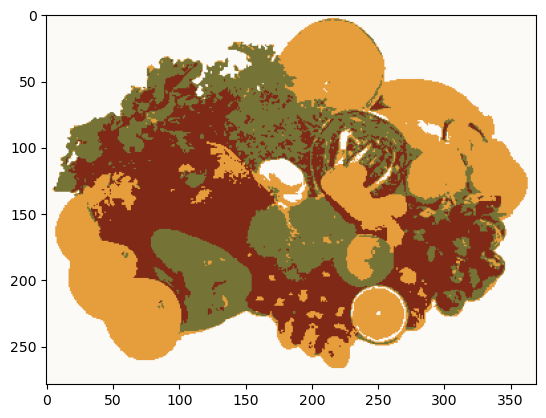

In [29]:
k = 4
cluster_4_image_fit = Kmeans_image(data_from_image, k)
cluster_4_image_fit.fit(debug=False, ceil=2)

cluster_4_image_reconstruct = cluster_4_image_fit.construct_image_from_cluster()
plt.imshow(cluster_4_image_reconstruct)
plt.show()